## Problem

**Датасет:** Kepler Exoplanet Search Results (NASA);

**N** $\approx$ 9564 объекта, d = 50 признаков;

**Целевая переменная:** `koi_disposition` - статус кандидата:
- `CONFIRMED` - подтверждённая планета (~28%);
- `CANDIDATE` - кандидат (~20%);
- `FALSE POSITIVE` - ложное срабатывание (~51%).

**Задача:** многоклассовая классификация - по физическим и орбитальным характеристикам объекта предсказать его статус.


## Setup

In [122]:
import warnings
warnings.filterwarnings("ignore")

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.model_selection import train_test_split, GridSearchCV, cross_val_score
from sklearn.preprocessing import StandardScaler
from sklearn.impute import SimpleImputer
from sklearn.neighbors import KNeighborsClassifier
from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import (accuracy_score, classification_report, f1_score, ConfusionMatrixDisplay)

sns.set_theme(style="whitegrid")
plt.rcParams["figure.figsize"] = (10, 5)
pd.set_option("display.max_columns", 100)
RANDOM_STATE = 42

## Reading Data

In [123]:
df = pd.read_csv("../Data/cumulative.csv")
print("Size:", df.shape)
df.head()

Size: (9564, 50)


,rowid,kepid,kepoi_name,kepler_name,koi_disposition,koi_pdisposition,koi_score,koi_fpflag_nt,koi_fpflag_ss,koi_fpflag_co,koi_fpflag_ec,koi_period,koi_period_err1,koi_period_err2,koi_time0bk,koi_time0bk_err1,koi_time0bk_err2,koi_impact,koi_impact_err1,koi_impact_err2,koi_duration,koi_duration_err1,koi_duration_err2,koi_depth,koi_depth_err1,koi_depth_err2,koi_prad,koi_prad_err1,koi_prad_err2,koi_teq,koi_teq_err1,koi_teq_err2,koi_insol,koi_insol_err1,koi_insol_err2,koi_model_snr,koi_tce_plnt_num,koi_tce_delivname,koi_steff,koi_steff_err1,koi_steff_err2,koi_slogg,koi_slogg_err1,koi_slogg_err2,koi_srad,koi_srad_err1,koi_srad_err2,ra,dec,koi_kepmag
0,1,10797460,K00752.01,Kepler-227 b,CONFIRMED,CANDIDATE,1.000,0,0,0,0,9.488036,2.775000e-05,-2.775000e-05,170.538750,0.002160,-0.002160,0.146,0.318,-0.146,2.95750,0.08190,-0.08190,615.8,19.5,-19.5,2.26,0.26,-0.15,793.0,NaN,NaN,93.59,29.45,-16.65,35.8,1.0,q1_q17_dr25_tce,5455.0,81.0,-81.0,4.467,0.064,-0.096,0.927,0.105,-0.061,291.93423,48.141651,15.347
1,2,10797460,K00752.02,Kepler-227 c,CONFIRMED,CANDIDATE,0.969,0,0,0,0,54.418383,2.479000e-04,-2.479000e-04,162.513840,0.003520,-0.003520,0.586,0.059,-0.443,4.50700,0.11600,-0.11600,874.8,35.5,-35.5,2.83,0.32,-0.19,443.0,NaN,NaN,9.11,2.87,-1.62,25.8,2.0,q1_q17_dr25_tce,5455.0,81.0,-81.0,4.467,0.064,-0.096,0.927,0.105,-0.061,291.93423,48.141651,15.347
2,3,10811496,K00753.01,NaN,FALSE POSITIVE,FALSE POSITIVE,0.000,0,1,0,0,19.899140,1.494000e-05,-1.494000e-05,175.850252,0.000581,-0.000581,0.969,5.126,-0.077,1.78220,0.03410,-0.03410,10829.0,171.0,-171.0,14.60,3.92,-1.31,638.0,NaN,NaN,39.30,31.04,-10.49,76.3,1.0,q1_q17_dr25_tce,5853.0,158.0,-176.0,4.544,0.044,-0.176,0.868,0.233,-0.078,297.00482,48.134129,15.436
3,4,10848459,K00754.01,NaN,FALSE POSITIVE,FALSE POSITIVE,0.000,0,1,0,0,1.736952,2.630000e-07,-2.630000e-07,170.307565,0.000115,-0.000115,1.276,0.115,-0.092,2.40641,0.00537,-0.00537,8079.2,12.8,-12.8,33.46,8.50,-2.83,1395.0,NaN,NaN,891.96,668.95,-230.35,505.6,1.0,q1_q17_dr25_tce,5805.0,157.0,-174.0,4.564,0.053,-0.168,0.791,0.201,-0.067,285.53461,48.285210,15.597
4,5,10854555,K00755.01,Kepler-664 b,CONFIRMED,CANDIDATE,1.000,0,0,0,0,2.525592,3.761000e-06,-3.761000e-06,171.595550,0.001130,-0.001130,0.701,0.235,-0.478,1.65450,0.04200,-0.04200,603.3,16.9,-16.9,2.75,0.88,-0.35,1406.0,NaN,NaN,926.16,874.33,-314.24,40.9,1.0,q1_q17_dr25_tce,6031.0,169.0,-211.0,4.438,0.070,-0.210,1.046,0.334,-0.133,288.75488,48.226200,15.509


In [124]:
df.info(verbose=False)
print("\nClass destribution:")
print(df["koi_disposition"].value_counts(dropna=False))

<class 'pandas.DataFrame'>
RangeIndex: 9564 entries, 0 to 9563
Columns: 50 entries, rowid to koi_kepmag
dtypes: float64(39), int64(6), str(5)
memory usage: 3.6 MB

Class destribution:
koi_disposition
FALSE POSITIVE    5023
CONFIRMED         2293
CANDIDATE         2248
Name: count, dtype: int64


## Train / Test splitting

In [125]:
df = df.dropna(subset=["koi_disposition"]).reset_index(drop=True)

X = df.drop(columns=["koi_disposition", "koi_pdisposition"]) # pdisposition is a Kepler's prediction of the same thing
y = df["koi_disposition"]

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.25, random_state=RANDOM_STATE, stratify=y
)
print("Train:", X_train.shape, " Test:", X_test.shape)
print("Class destribution in Train:\n", y_train.value_counts(normalize=True))

Train: (7173, 48)  Test: (2391, 48)
Class destribution in Train:
 koi_disposition
FALSE POSITIVE    0.525164
CONFIRMED         0.239788
CANDIDATE         0.235048
Name: proportion, dtype: float64


Данные разбиты на train (7173) и test (2391) со стратификацией по `koi_disposition`. 
Доли классов в train (52.5% / 24.0% / 23.5%) совпадают с исходным распределением - стратификация корректно сохранила дисбаланс.

## Visualization

In [126]:
desc = X_train.describe().T
desc

,count,mean,std,min,25%,50%,75%,max
rowid,7173.0,4.755828e+03,2.757669e+03,1.000000e+00,2.343000e+03,4.766000e+03,7.147000e+03,9.563000e+03
kepid,7173.0,7.681665e+06,2.648343e+06,7.574500e+05,5.551504e+06,7.906882e+06,9.838975e+06,1.293514e+07
koi_score,6009.0,4.826740e-01,4.774610e-01,0.000000e+00,0.000000e+00,3.630000e-01,9.990000e-01,1.000000e+00
koi_fpflag_nt,7173.0,1.891817e-01,3.916802e-01,0.000000e+00,0.000000e+00,0.000000e+00,0.000000e+00,1.000000e+00
koi_fpflag_ss,7173.0,2.328175e-01,4.226564e-01,0.000000e+00,0.000000e+00,0.000000e+00,0.000000e+00,1.000000e+00
koi_fpflag_co,7173.0,1.936428e-01,3.951798e-01,0.000000e+00,0.000000e+00,0.000000e+00,0.000000e+00,1.000000e+00
koi_fpflag_ec,7173.0,1.196152e-01,3.245337e-01,0.000000e+00,0.000000e+00,0.000000e+00,0.000000e+00,1.000000e+00
koi_period,7173.0,8.016014e+01,1.539456e+03,2.996978e-01,2.722882e+00,9.605060e+00,4.006915e+01,1.299958e+05
koi_period_err1,6822.0,2.174603e-03,8.545010e-03,0.000000e+00,5.242500e-06,3.436000e-05,2.739000e-04,1.725000e-01
koi_period_err2,6822.0,-2.174603e-03,8.545010e-03,-1.725000e-01,-2.739000e-04,-3.436000e-05,-5.242500e-06,0.000000e+00


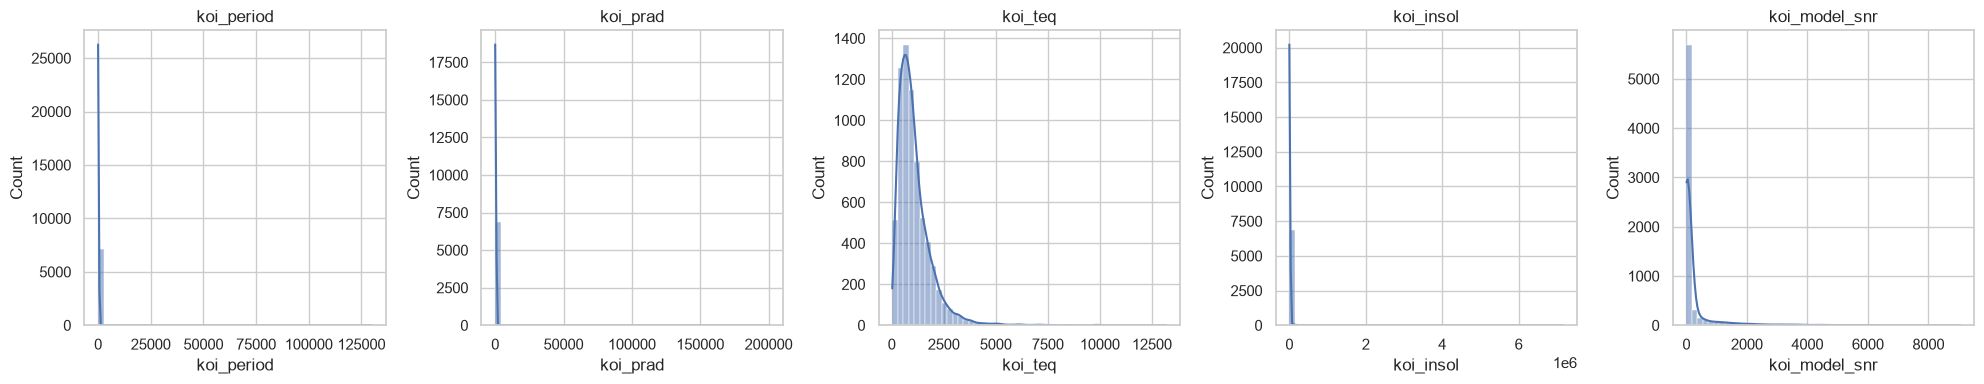

In [127]:
# Plots for some of the key attributes
key_cols = ["koi_period", "koi_prad", "koi_teq", "koi_insol", "koi_model_snr"]
key_cols = [c for c in key_cols if c in X_train]

fig, axes = plt.subplots(1, len(key_cols), figsize=(20, 4))
for ax, col in zip(axes, key_cols):
    sns.histplot(X_train[col].dropna(), bins=50, ax=ax, kde=True)
    ax.set_title(col)
plt.tight_layout()
plt.show()

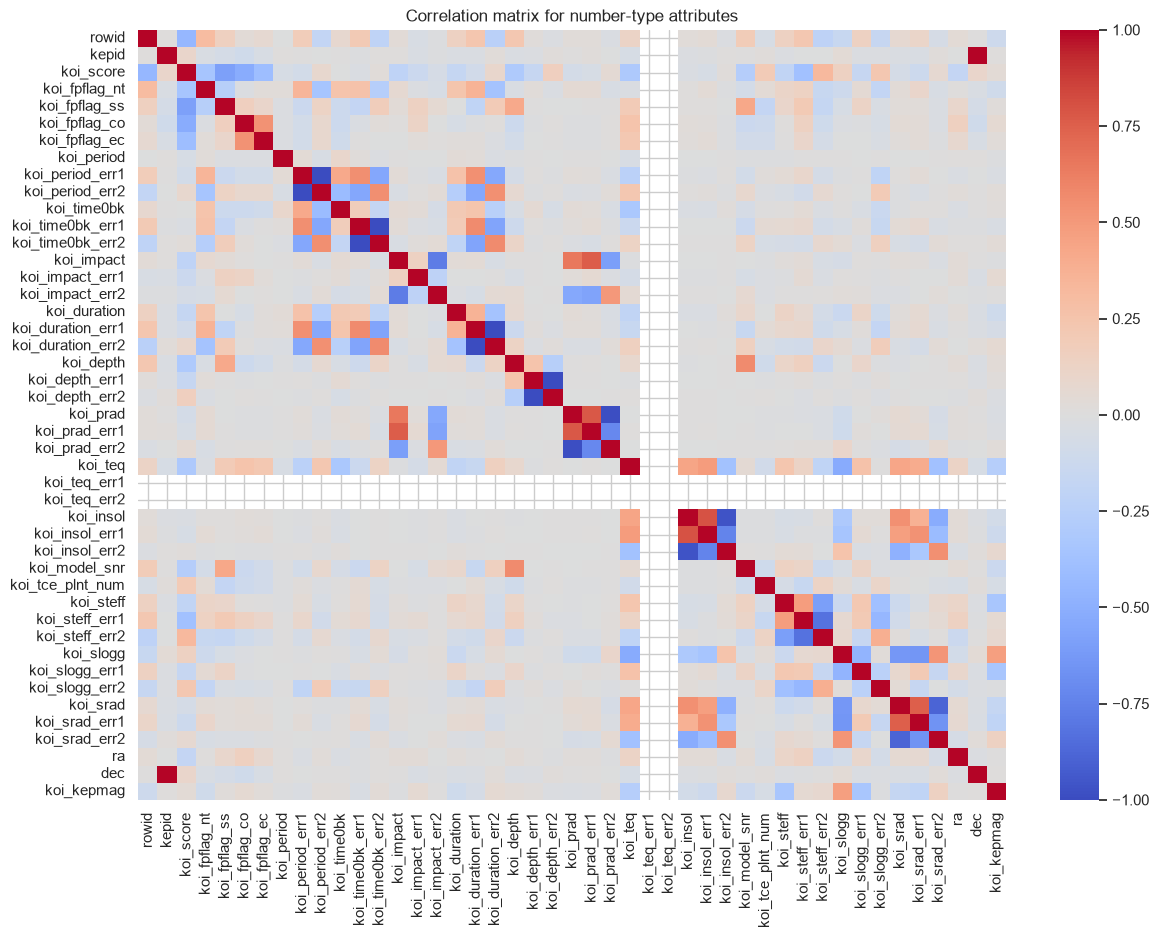

,col1,col2,corr
42,dec,kepid,0.993629
24,koi_prad,koi_prad_err2,-0.990213
27,koi_insol,koi_insol_err2,-0.961322
40,koi_srad,koi_srad_err2,-0.888831
34,koi_steff_err1,koi_steff_err2,-0.826592
26,koi_insol,koi_insol_err1,0.803703
23,koi_prad,koi_prad_err1,0.778099
7,koi_impact,koi_impact_err2,-0.775124
9,koi_impact,koi_prad_err1,0.763962
39,koi_srad,koi_srad_err1,0.754553


In [128]:
# Corr matrix 
num_cols = X_train.select_dtypes(include=[np.number]).columns.tolist()

corr = X_train[num_cols].corr()
plt.figure(figsize=(14, 10))
sns.heatmap(corr, cmap="coolwarm", center=0, vmin=-1, vmax=1)
plt.title("Correlation matrix for number-type attributes")
plt.show()

# Top 10 most correlated attributes
high_corr = (corr.abs() > 0.5) & (corr.abs() < 1.0)
pairs = [(c1, c2, corr.loc[c1, c2]) for c1 in high_corr.index for c2 in high_corr.columns
         if high_corr.loc[c1, c2] and c1 < c2]
pd.DataFrame(pairs, columns=["col1", "col2", "corr"]).sort_values("corr", key=abs, ascending=False).head(10)

#### Интерпретация характеристик

1. Распределения сильно скошены (длинные правые хвосты на графиках): `koi_prad`, `koi_insol`, `koi_depth`, 
  `koi_model_snr`. Это типично для астрономии: большинство объектов - обычные газовые и каменистые планеты, 
  но встречаются редкие горячие юпитеры, гиганты и т.п.
2. Среднее плохо описывает данные: например, для `koi_prad` среднее = 113.2, медиана = 2.42, 
  max = 200346 - среднее вытянуто выбросами. Медиана кажется надёжнее.
3. Много сильно коррелированных пар (abs(corr) > 0.8), в основном это значения и ошибки их измерения 
  (`koi_prad` - `koi_prad_err2`, `koi_insol` - `koi_insol_err2`, ...).
4. Дисбаланс классов: FALSE POSITIVE ~52%, CONFIRMED ~24%, CANDIDATE ~24%. 
  Из-за этого метрика accuracy обманчива, как основную выберем macro-F1, т.к. она значительно лучше работает при сильным дисбалансе классов.

## Outliers

In [129]:
# 1.5*IQR
def outlier_share(s):
    s = s.dropna()
    q1, q3 = s.quantile([0.25, 0.75])
    iqr = q3 - q1
    return ((s < q1 - 1.5*iqr) | (s > q3 + 1.5*iqr)).mean() * 100

out_shares = pd.Series({c: outlier_share(X_train[c]) for c in key_cols})
print("Outliers, %:")
print(out_shares.round(2))

mask = pd.DataFrame({c: ((X_train[c] < X_train[c].quantile(.25) - 1.5*(X_train[c].quantile(.75)-X_train[c].quantile(.25))) |
                         (X_train[c] > X_train[c].quantile(.75) + 1.5*(X_train[c].quantile(.75)-X_train[c].quantile(.25))))
                      for c in key_cols})
print(f"\nAt least one outlier: {mask.any(axis=1).mean()*100:.1f}%")

Outliers, %:
koi_period       16.48
koi_prad         15.34
koi_teq           4.63
koi_insol        15.51
koi_model_snr    17.65
dtype: float64

At least one outlier: 45.2%


#### Обработка выбросов

По правилу 1.5·IQR доля выбросов достигает 15–18% для ключевых признаков, а **45.2% объектов** 
имеют хотя бы один выброс. Удалять такую долю нельзя, т.к. потеряем слишком много данных.

Заметим, что в астрономии выбросы - это реальные физические объекты (горячие юпитеры, 
гиганты, редкие события), а не ошибки измерения. Их удаление исказит выборку.

Поэтому, **выбросы удаляться не будут**.

## Missing Values

In [130]:
miss = X_train.isna().mean().sort_values(ascending=False)
print("Missing value statistics:")
print((miss[miss > 0] * 100).round(2))

cols_to_drop = miss[miss > 0.5].index.tolist()
print("\nColumns with > 50% misses (removed):", cols_to_drop)
X_train = X_train.drop(columns=cols_to_drop)
X_test = X_test.drop(columns=cols_to_drop)

# Fill non-critical misses
num_cols = X_train.select_dtypes(include=[np.number]).columns.tolist()
cat_cols = X_train.select_dtypes(exclude=[np.number]).columns.tolist()

num_imputer = SimpleImputer(strategy="median")
cat_imputer = SimpleImputer(strategy="most_frequent")

X_train[num_cols] = num_imputer.fit_transform(X_train[num_cols])
X_test[num_cols]  = num_imputer.transform(X_test[num_cols])
X_train[cat_cols] = cat_imputer.fit_transform(X_train[cat_cols])
X_test[cat_cols]  = cat_imputer.transform(X_test[cat_cols])

Missing value statistics:
koi_teq_err2         100.00
koi_teq_err1         100.00
kepler_name           76.01
koi_score             16.23
koi_steff_err2         5.30
koi_srad_err1          5.16
koi_slogg_err2         5.16
koi_slogg_err1         5.16
koi_srad_err2          5.16
koi_steff_err1         5.16
koi_period_err1        4.89
koi_period_err2        4.89
koi_time0bk_err1       4.89
koi_time0bk_err2       4.89
koi_depth_err1         4.89
koi_depth_err2         4.89
koi_duration_err1      4.89
koi_duration_err2      4.89
koi_impact_err1        4.89
koi_impact_err2        4.89
koi_srad               3.95
koi_slogg              3.95
koi_steff              3.95
koi_depth              3.95
koi_prad_err1          3.95
koi_impact             3.95
koi_model_snr          3.95
koi_prad_err2          3.95
koi_teq                3.95
koi_prad               3.95
koi_tce_delivname      3.86
koi_tce_plnt_num       3.86
koi_insol              3.49
koi_insol_err2         3.49
koi_insol_err1        

Колоники с числом пропусков >50% удаляются:
`koi_teq_err1`, `koi_teq_err2` - 100% пропусков, `kepler_name` - 76%.

Остальные пропуски (ниже порога в 50%) заполняются медианой (для числовых) и модой (для категориальных).
Вместо среднего выбрана медиана выбрана, т.к. распределения сильно скошены.

## Categorial

In [131]:
print("Categorial columns:", cat_cols)

id_like = [c for c in cat_cols if X_train[c].nunique() > 100]
print("Removing (too many unique values):", id_like)
X_train = X_train.drop(columns=id_like)
X_test = X_test.drop(columns=id_like)

cat_cols = [c for c in cat_cols if c not in id_like]
if cat_cols:
    X_train = pd.get_dummies(X_train, columns=cat_cols, drop_first=True)
    X_test  = pd.get_dummies(X_test,  columns=cat_cols, drop_first=True)
    X_train, X_test = X_train.align(X_test, join="left", axis=1, fill_value=0)

print("Final:", X_train.shape)

Categorial columns: ['kepoi_name', 'koi_tce_delivname']
Removing (too many unique values): ['kepoi_name']
Final: (7173, 45)


#### Обработка категориальных признаков

1. Ужадяем столбцы-идентификаторы, для которых сликшом много уникальных значений: 
`kepoi_name` - идентификатор объекта, не несущий полезной информации о его классе.
2. Остальные (остался только `koi_tce_delivname`) по методу One-Hot Encoding превращаем в бинарные признаки.
После применения One-Hot итоговая размерность: **45 признаков**).

## Normalization

In [132]:
scaler = StandardScaler()
X_train_scaled = scaler.fit_transform(X_train)
X_test_scaled  = scaler.transform(X_test)
print("Average:", np.round(X_train_scaled.mean(axis=0), 3))
print("Std:", np.round(X_train_scaled.std(axis=0), 3))

Average: [ 0.  0.  0.  0. -0.  0.  0. -0. -0.  0.  0.  0. -0.  0. -0.  0. -0.  0.
 -0. -0.  0. -0. -0.  0.  0.  0. -0.  0. -0.  0.  0.  0.  0. -0.  0. -0.
  0. -0. -0. -0. -0.  0.  0. -0.  0.]
Std: [1. 1. 1. 1. 1. 1. 1. 1. 1. 1. 1. 1. 1. 1. 1. 1. 1. 1. 1. 1. 1. 1. 1. 1.
 1. 1. 1. 1. 1. 1. 1. 1. 1. 1. 1. 1. 1. 1. 1. 1. 1. 1. 1. 1. 1.]


Нормализация обязательна, т.к. признаки имеют разные масштабы:
(`koi_prad` ~ 10, `koi_period` ~ 10^2, `koi_insol` ~ 10^3, ...). Без нормализации признаки 
с большим разбросом доминировали бы в евклидовом расстоянии.

Для нормализации используется StandardScaler, обученный только на train.
После преобразования: mean (среднее) $\approx$ 0, std (среднеквадратическое отклонение) $\approx$ 1.

## Classification

In [133]:
knn = KNeighborsClassifier(n_neighbors=5, weights="distance", n_jobs=-1)
knn.fit(X_train_scaled, y_train)

y_train_pred = knn.predict(X_train_scaled)
y_test_pred  = knn.predict(X_test_scaled)

print(f"Accuracy train: {accuracy_score(y_train, y_train_pred):.4f}")
print(f"Accuracy test : {accuracy_score(y_test,  y_test_pred):.4f}")

Accuracy train: 1.0000
Accuracy test : 0.8549


#### Выбор классификатора

Выбран **kNN**, т.к.:
- датасет небольшой ($\approx 7000$ объектов в train), следовательно kNN отработает быстро;
- после нормализации и One-Hot признаки стали сопоставимыми;
- kNN не требует предположений о форме разделяющей поверхности.

Начальное значение параметра `k` (число ближайших соседей) задано как 5. 
Параметр `weights="distance"` означает, что ближние соседи весят больше, это полезно при сильном дисбалансе классов.

## Errors

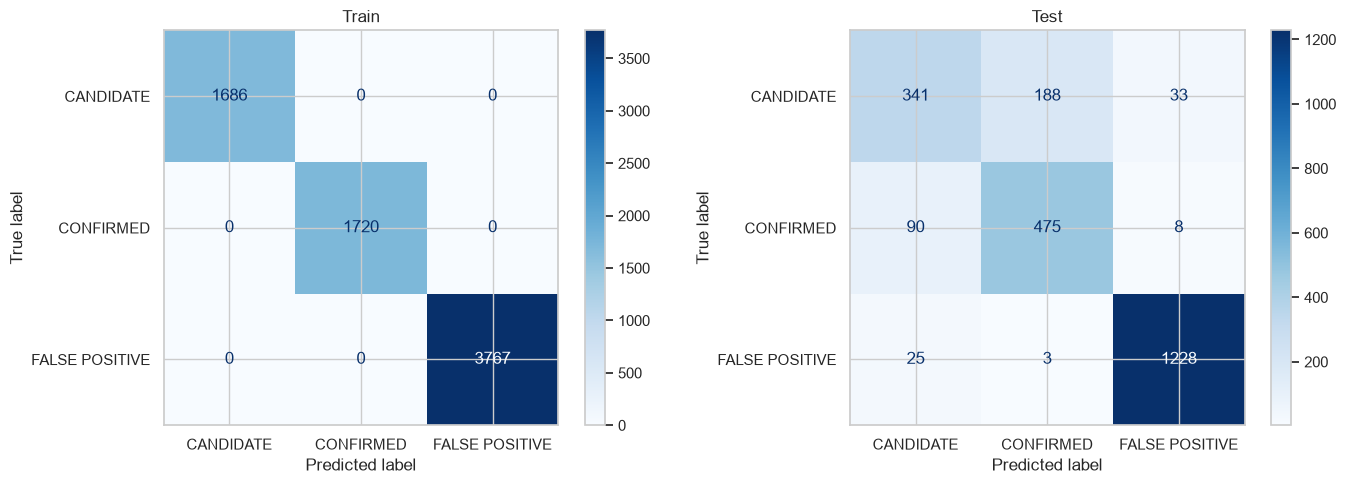

Classification report (test):
                precision    recall  f1-score   support

     CANDIDATE      0.748     0.607     0.670       562
     CONFIRMED      0.713     0.829     0.767       573
FALSE POSITIVE      0.968     0.978     0.973      1256

      accuracy                          0.855      2391
     macro avg      0.810     0.804     0.803      2391
  weighted avg      0.855     0.855     0.852      2391



In [134]:
fig, axes = plt.subplots(1, 2, figsize=(14, 5))
ConfusionMatrixDisplay.from_predictions(y_train, y_train_pred, ax=axes[0], cmap="Blues")
axes[0].set_title("Train")
ConfusionMatrixDisplay.from_predictions(y_test, y_test_pred, ax=axes[1], cmap="Blues")
axes[1].set_title("Test")
plt.tight_layout()
plt.show()

print("Classification report (test):")
print(classification_report(y_test, y_test_pred, digits=3))

#### Выводы по ошибкам

При k=5: accuracy(train) = 1.0, accuracy(test) = 0.855, похоже на **сильное переобучение** 
  (скорее всего модель запомнила train).

Класс FALSE POSITIVE распознаётся почти идеально (F1 = 0.973), что объясняется его доминированием в выборке (~52.5%) и физическим несходством с реальными планетами. 
Класс CONFIRMED показал F1 = 0.767 при высокой чувствительности (0.829) и умеренном показателе precision (0.713), т.е. модель довольно уверенно находит подтверждённые планеты, но часть CANDIDATE ошибочно распознаёт как CONFIRMED, поскольку по физическим признакам эти классы близки. Наихудший результат виден у класса CANDIDATE (F1 = 0.670): его чувствительность составляет всего 0.607, то есть около 40% кандидатов теряются, в основном из-за смещения в сторону более частого FALSE POSITIVE. 
Итоговая метрика macro-F1 = 0.803 отражает наблюдаемые эффекты: в отличие от accuracy (0.855), она не прячет слабое качество на CANDIDATE за счёт хорошего распознавания доминирующего класса.

Best k: 15
Best macro-F1 (CV): 0.8088


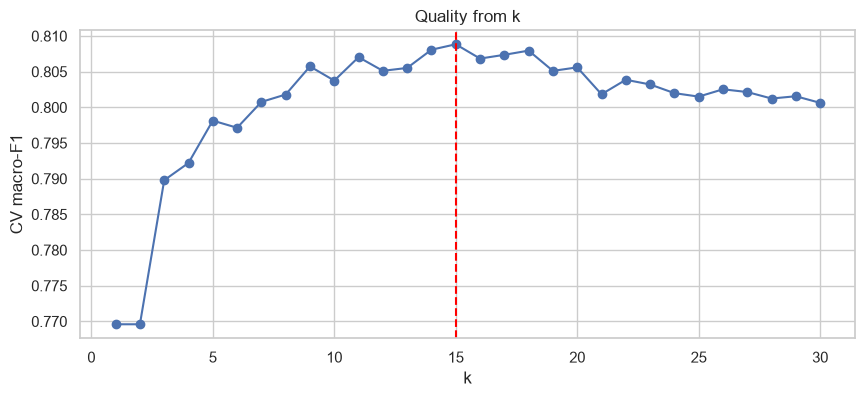

In [135]:
param_grid = {"n_neighbors": list(range(1, 31))}
grid = GridSearchCV(
    KNeighborsClassifier(weights="distance", n_jobs=-1),
    param_grid, cv=5, scoring="f1_macro", n_jobs=-1
)
grid.fit(X_train_scaled, y_train)

print("Best k:", grid.best_params_["n_neighbors"])
print("Best macro-F1 (CV):", round(grid.best_score_, 4))

ks = param_grid["n_neighbors"]
accs = [grid.cv_results_["mean_test_score"][i] for i in range(len(ks))]
plt.figure(figsize=(10, 4))
plt.plot(ks, accs, marker="o")
plt.xlabel("k"); plt.ylabel("CV macro-F1"); plt.title("Quality from k")
plt.axvline(grid.best_params_["n_neighbors"], color="red", ls="--")
plt.show()

#### Подбор оптимального k

Для подбора оптимального k перебираются значения от 1 до 30. Для каждого значения модель обучается 5 раз по схеме кросс-валидации (CV), затем подсчитывается среднее значение метрики macro-F1.

**Итого:** Оптимальное k = 15 (CV macro-F1 = 0.8088). При таком k переобучение снижается (заметно, т.к. train accuracy уже не 1.0), а качество на test 
  остаётся стабильным (test macro-F1 = 0.8082).


In [136]:
models = {
    "LogisticRegression": LogisticRegression(max_iter=2000, n_jobs=-1),
    "RandomForest": RandomForestClassifier(n_estimators=300, n_jobs=-1, random_state=RANDOM_STATE),
}
results = {"kNN": (grid.best_score_, f1_score(y_test, grid.predict(X_test_scaled), average="macro"))}
for name, m in models.items():
    m.fit(X_train_scaled, y_train)
    pred = m.predict(X_test_scaled)
    results[name] = (cross_val_score(m, X_train_scaled, y_train, cv=3, scoring="f1_macro", n_jobs=-1).mean(),
                     f1_score(y_test, pred, average="macro"))
    print(f"{name}: test macro-F1 = {results[name][1]:.4f}")

pd.DataFrame(results, index=["CV macro-F1", "Test macro-F1"]).T.round(4)

LogisticRegression: test macro-F1 = 0.8619
RandomForest: test macro-F1 = 0.8853


,CV macro-F1,Test macro-F1
kNN,0.8088,0.8082
LogisticRegression,0.8406,0.8619
RandomForest,0.8640,0.8853


#### Сравнение классификаторов

- **RandomForest - лучшая модель** (test macro-F1 = **0.885**): он устойчив к выбросам, не требует нормализации, хорошо работает с дисбалансом и нелинейностями.
- LogisticRegression (**0.862**) - проще и интерпретируемее, ненамного хуже.
- kNN (**0.808**) - слабее всех: страдает от размерности (45 признаков), чувствителен к выбросам и дисбалансу.

**Вывод:** для данной задачи RandomForest предпочтительнее kNN.

## Общие выводы

В работе был рассмотрен датасет Kepler Exoplanet Search Results (9564 объекта, 50 признаков, из них 45 числовых и 5 категориальных или идентификаторов). Целевая переменная koi_disposition принимает три значения (`CONFIRMED`, `CANDIDATE`, `FALSE POSITIVE`), поэтому задача является многоклассовой классификацией. Классы распределены неравномерно (примерно 52.5% / 24.0% / 23.5%), из-за чего в качестве основной метрики был выбран macro-F1, а не accuracy: последняя при accuracy = 0.855 скрывает слабое качество на классе `CANDIDATE` (F1 = 0.670) за счёт почти идеального распознавания `FALSE POSITIVE` (F1 = 0.973).

При предобработке были удалены столбцы с более чем 50% пропусков (`koi_teq_err1/2`, `kepler_name`), остальные пропуски заполнены медианой и модой. Выбросы, составляющие 45.2% объектов, удалять не стали, поскольку в астрономии они соответствуют реальным физическим объектам. Категориальные признаки обработаны через One-Hot Encoding, для kNN выполнена нормализация `StandardScaler` - без неё евклидово расстояние определялось бы признаками с наибольшим разбросом.

Базовый kNN при k = 5 сильно переобучался (accuracy на train = 1.0, на test = 0.855). По результатам 5-кратной кросс-валидации с метрикой macro-F1 оптимальным оказалось k = 15 (CV macro-F1 = 0.809). Сравнение моделей показало, что `RandomForest` даёт лучший результат (test macro-F1 = 0.885), `LogisticRegression` - 0.862, kNN - 0.808. `RandomForest` лучше остальных справляется с выбросами, нелинейностями и дисбалансом классов, тогда как kNN в условиях 45 признаков страдает от проклятия размерности.